# Figure 9: spot detectability through the VAE against spot count

Section 4.6, `fig:pr_auc_spot_count`. The conditional distribution of
the area under the precision-recall curve between the true and
reconstructed spot masks, against the number of injected spots, over
every surface in the holdout, with the conditional median and the
marginal distribution of the injected spot count above.

Laid out as figure 8: the map is normalised down each column, so a
column reads as P(PR-AUC | spot count) rather than as a count, and the
colour scale is the same conditional probability.

The pixel counts are area weighted and the sweep is over the
reconstruction threshold with the truth mask fixed at 0.9, which is
`metrics.pr_auc` under whole-sphere weighting. The pass is cached, so
re-running this notebook is immediate.

## Imports

In [1]:
from _setup import *

from starspot_sbi.pipeline import decode_ceiling_coeffs

## Setup

The whole holdout, the chunk size the pass works in, the spot counts
the columns run over, and the PR-AUC window the map covers.

In [2]:
DEVICE = 'cuda'
CHUNK = 2000               # surfaces held in memory at once
COUNTS = np.arange(1, 12)
N_LEVELS = 30              # rows of the column-normalised map
PRAUC_MIN = 0.9            # bottom of the plotted PR-AUC axis
CACHE = os.path.join(CACHES, 'fig09_prauc.npz')

## Selecting the sample

Every surface in the holdout index.

In [3]:
idx = load_meta().index.values
n_spots = load_meta().loc[idx, 'n_spots'].values
print(f'{len(idx):,} holdout surfaces, the whole set, '
      f'spot counts {n_spots.min()} to {n_spots.max()}')

100,000 holdout surfaces, the whole set, spot counts 1 to 11


## Inference

Reconstructs every surface at the encoder mean and sweeps the
detection threshold against the true mask, one chunk in memory at a
time: the holdout is 100,000 surfaces and the renders would not fit
otherwise.

In [4]:
def score_all():
    """Whole-sphere PR-AUC for every surface in the holdout."""
    vae, stats = load_autoencoder(device=DEVICE)
    out = np.empty(len(idx))
    for a in range(0, len(idx), CHUNK):
        b = min(a + CHUNK, len(idx))
        coeffs = np.stack([np.load(os.path.join(HOLDOUT, 'surfaces',
                                                f'surface_{i:07d}.npy'))
                           for i in idx[a:b]])
        truth_real = np.stack([coeffs_to_real(c) for c in coeffs])
        rec = decode_ceiling_coeffs(coeffs, vae, stats, device=DEVICE)
        timgs = render_draws(truth_real, device=DEVICE)
        rimgs = render_draws(rec, device=DEVICE)
        out[a:b] = [metrics.pr_auc(timgs[k], rimgs[k], 0.0, 'full')
                    for k in range(b - a)]
        print(f'  {b:,} / {len(idx):,}', flush=True)
    return dict(idx=idx, prauc=out)


os.makedirs(CACHES, exist_ok=True)
z = np.load(CACHE) if os.path.exists(CACHE) else None
# the guard checks the scored population, not just that a file is there, so a
# different holdout or sample size recomputes instead of being silently reused
if z is not None and z['prauc'].size == len(idx) and np.array_equal(z['idx'],
                                                                    idx):
    d = {k: z[k] for k in z.files}
    print(f'PR-AUC read from {os.path.relpath(CACHE, REPO)}')
else:
    d = score_all()                 # the whole holdout; tens of minutes
    np.savez(CACHE, **d)
    print(f'PR-AUC written to {os.path.relpath(CACHE, REPO)}')

prauc = d['prauc']
scored = np.isfinite(prauc)
print(f'{prauc.size:,} surfaces, {np.sum(~scored):,} with an empty truth '
      f'mask (nan)')

/home/conaire/miniconda3/envs/paper2_gpu/lib/python3.12/site-packages/torch/nn/modules/transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


  2,000 / 100,000
  4,000 / 100,000
  6,000 / 100,000
  8,000 / 100,000
  10,000 / 100,000
  12,000 / 100,000
  14,000 / 100,000
  16,000 / 100,000
  18,000 / 100,000
  20,000 / 100,000
  22,000 / 100,000
  24,000 / 100,000
  26,000 / 100,000
  28,000 / 100,000
  30,000 / 100,000
  32,000 / 100,000
  34,000 / 100,000
  36,000 / 100,000
  38,000 / 100,000
  40,000 / 100,000
  42,000 / 100,000
  44,000 / 100,000
  46,000 / 100,000
  48,000 / 100,000
  50,000 / 100,000
  52,000 / 100,000
  54,000 / 100,000
  56,000 / 100,000
  58,000 / 100,000
  60,000 / 100,000
  62,000 / 100,000
  64,000 / 100,000
  66,000 / 100,000
  68,000 / 100,000
  70,000 / 100,000
  72,000 / 100,000
  74,000 / 100,000
  76,000 / 100,000
  78,000 / 100,000
  80,000 / 100,000
  82,000 / 100,000
  84,000 / 100,000
  86,000 / 100,000
  88,000 / 100,000
  90,000 / 100,000
  92,000 / 100,000
  94,000 / 100,000
  96,000 / 100,000
  98,000 / 100,000
  100,000 / 100,000
PR-AUC written to caches/fig09_prauc.npz
100,000 surf

In [5]:
# One column per spot count, normalised to the surfaces of that count, so a
# cell is P(PR-AUC | spot count). The map starts at PRAUC_MIN; the tail below
# it is counted rather than drawn, since one long tail would flatten the scale
# everywhere else.
y_edges = np.linspace(PRAUC_MIN, 1.0, N_LEVELS + 1)
density = np.full((N_LEVELS, COUNTS.size), np.nan)
med = np.empty(COUNTS.size)
n_per_count = np.empty(COUNTS.size, dtype=int)
n_below = np.empty(COUNTS.size, dtype=int)
for j, n in enumerate(COUNTS):
    inside = scored & (n_spots == n)
    hist, _ = np.histogram(prauc[inside], bins=y_edges)
    density[:, j] = hist / max(inside.sum(), 1)
    med[j] = np.median(prauc[inside])
    n_per_count[j] = inside.sum()
    n_below[j] = np.sum(prauc[inside] < PRAUC_MIN)
print(f'median PR-AUC {med[0]:.4f} at one spot, {med[-1]:.4f} at '
      f'{COUNTS[-1]}; {n_below.sum():,} surfaces '
      f'({n_below.sum() / scored.sum() * 100:.2f} per cent) fall below '
      f'{PRAUC_MIN} and sit outside the map')

median PR-AUC 0.9851 at one spot, 0.9599 at 11; 662 surfaces (0.66 per cent) fall below 0.9 and sit outside the map


## Plotting

Draws the figure from the names bound above.

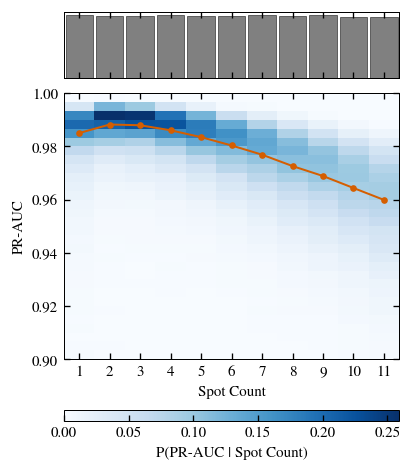

In [6]:
fig, (ax0, ax) = plt.subplots(2, 1, figsize=(COL, COL * 1.15),
                              sharex=True,
                              gridspec_kw={'height_ratios': [1, 4]})
ax0.hist(n_spots, bins=np.arange(0.5, 12.5), color=GRAY,
         edgecolor='black', lw=0.3, rwidth=0.9)
ax0.set_yticks([])

pc = ax.pcolormesh(np.arange(0.5, 12.0), y_edges, density, cmap='Blues',
                   vmin=0.0, rasterized=True)
ax.plot(COUNTS, med, color=RED, lw=1.2, marker='o', ms=3)
ax.set_ylim(PRAUC_MIN, 1.0)
ax.set_xticks(COUNTS)
ax.set_xlabel('Spot Count')
ax.set_ylabel('PR-AUC')

fig.colorbar(pc, ax=ax, orientation='horizontal', location='bottom',
             pad=0.04, fraction=0.05, aspect=30,
             label='P(PR-AUC | Spot Count)')

## Saving and caption numbers

Writes the pdf and png, then prints the numbers the Section 4.6 text
quotes: the median at one spot and at eleven.

In [7]:
save_fig(fig, 'fig09_pr_auc_spot_count')
for j, n in enumerate(COUNTS):
    print(f'{n:2d} spots: median PR-AUC {med[j]:.4f}, '
          f'n {n_per_count[j]:,}, {n_below[j]:,} below {PRAUC_MIN}')
print(f'\ndecline from one to {COUNTS[-1]} spots: {med[0]:.3f} to '
      f'{med[-1]:.3f}')
print(f'the maximum sits at {COUNTS[int(np.argmax(med))]} spots '
      f'({med.max():.3f})')

wrote notebooks/paper/figs/fig09_pr_auc_spot_count.pdf, notebooks/paper/figs/fig09_pr_auc_spot_count.png
 1 spots: median PR-AUC 0.9851, n 9,122, 294 below 0.9
 2 spots: median PR-AUC 0.9883, n 9,005, 53 below 0.9
 3 spots: median PR-AUC 0.9880, n 9,096, 26 below 0.9
 4 spots: median PR-AUC 0.9861, n 9,136, 15 below 0.9
 5 spots: median PR-AUC 0.9835, n 9,024, 17 below 0.9
 6 spots: median PR-AUC 0.9804, n 9,110, 16 below 0.9
 7 spots: median PR-AUC 0.9769, n 9,229, 20 below 0.9
 8 spots: median PR-AUC 0.9726, n 9,044, 25 below 0.9
 9 spots: median PR-AUC 0.9689, n 9,182, 37 below 0.9
10 spots: median PR-AUC 0.9644, n 8,973, 58 below 0.9
11 spots: median PR-AUC 0.9599, n 8,973, 101 below 0.9

decline from one to 11 spots: 0.985 to 0.960
the maximum sits at 2 spots (0.988)
